In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score)

In [2]:
df = pd.read_csv("Titanic-Dataset.csv")
print("Dataset shape:", df.shape)

Dataset shape: (891, 12)


In [3]:
target = "Survived"
predictors = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
model_df = df[[target] + predictors].dropna()

X = model_df[predictors]
y = model_df[target].astype(int)
print("Target distribution:\n", y.value_counts(normalize=True).round(3))

Target distribution:
 Survived
0    0.594
1    0.406
Name: proportion, dtype: float64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Train set size:", len(X_train), "| Test set size:", len(X_test))

Train set size: 571 | Test set size: 143


In [5]:
results, preds, probs = [], {}, {}

def evaluate(name, classifier):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", classifier)
    ])
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)
    probs[name] = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision": precision_score(y_test, preds[name], zero_division=0),
        "Recall": recall_score(y_test, preds[name], zero_division=0),
        "F1": f1_score(y_test, preds[name], zero_division=0),
        "AUC": roc_auc_score(y_test, probs[name])
    })
    print(name, results[-1])
    return model

In [6]:
logistic = evaluate("Logistic Regression", LogisticRegression(max_iter=1000, random_state=42))
coef = logistic.named_steps["classifier"].coef_[0]
coef_table = pd.DataFrame({"Coefficient": coef, "Odds Ratio": np.exp(coef)}, index=predictors)
print(coef_table.round(4))

knn = evaluate("KNN (K=5)", KNeighborsClassifier(n_neighbors=5))
nb = evaluate("Gaussian Naive Bayes", GaussianNB())

Logistic Regression {'Model': 'Logistic Regression', 'Accuracy': 0.7062937062937062, 'Precision': 0.6904761904761905, 'Recall': 0.5, 'F1': 0.58, 'AUC': 0.7405679513184584}
        Coefficient  Odds Ratio
Pclass      -0.9962      0.3693
Age         -0.6674      0.5130
SibSp       -0.2715      0.7622
Parch        0.2396      1.2708
Fare         0.1169      1.1240
KNN (K=5) {'Model': 'KNN (K=5)', 'Accuracy': 0.6433566433566433, 'Precision': 0.5636363636363636, 'Recall': 0.5344827586206896, 'F1': 0.5486725663716814, 'AUC': 0.7150101419878296}
Gaussian Naive Bayes {'Model': 'Gaussian Naive Bayes', 'Accuracy': 0.6783216783216783, 'Precision': 0.6578947368421053, 'Recall': 0.43103448275862066, 'F1': 0.5208333333333334, 'AUC': 0.7144016227180526}


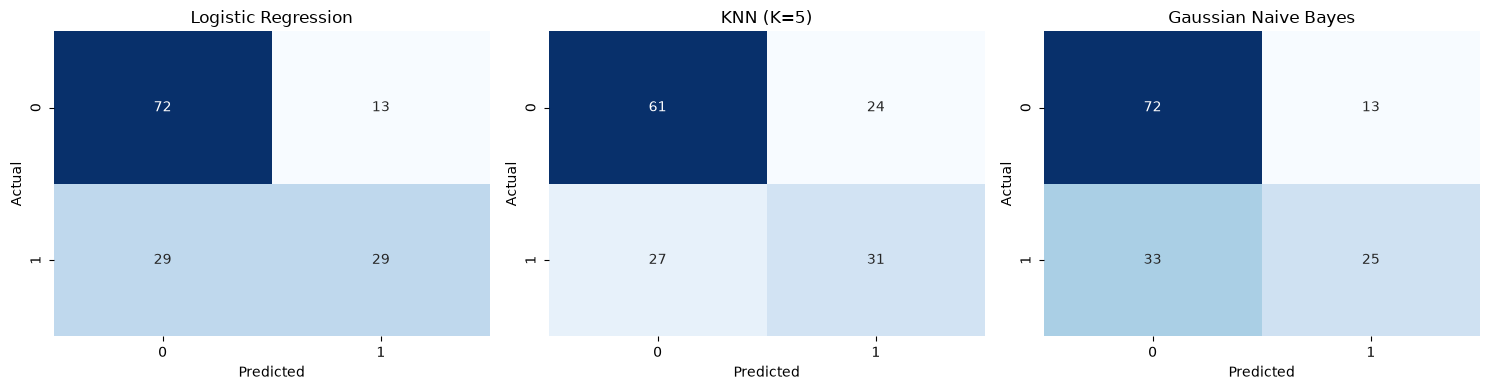

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.71      0.85      0.77        85
           1       0.69      0.50      0.58        58

    accuracy                           0.71       143
   macro avg       0.70      0.67      0.68       143
weighted avg       0.70      0.71      0.70       143

=== KNN (K=5) ===
              precision    recall  f1-score   support

           0       0.69      0.72      0.71        85
           1       0.56      0.53      0.55        58

    accuracy                           0.64       143
   macro avg       0.63      0.63      0.63       143
weighted avg       0.64      0.64      0.64       143

=== Gaussian Naive Bayes ===
              precision    recall  f1-score   support

           0       0.69      0.85      0.76        85
           1       0.66      0.43      0.52        58

    accuracy                           0.68       143
   macro avg       0.67      0.64      0.64       143

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, preds.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set(title=name, xlabel="Predicted", ylabel="Actual")
plt.tight_layout()
plt.show()

for name, pred in preds.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, zero_division=0))

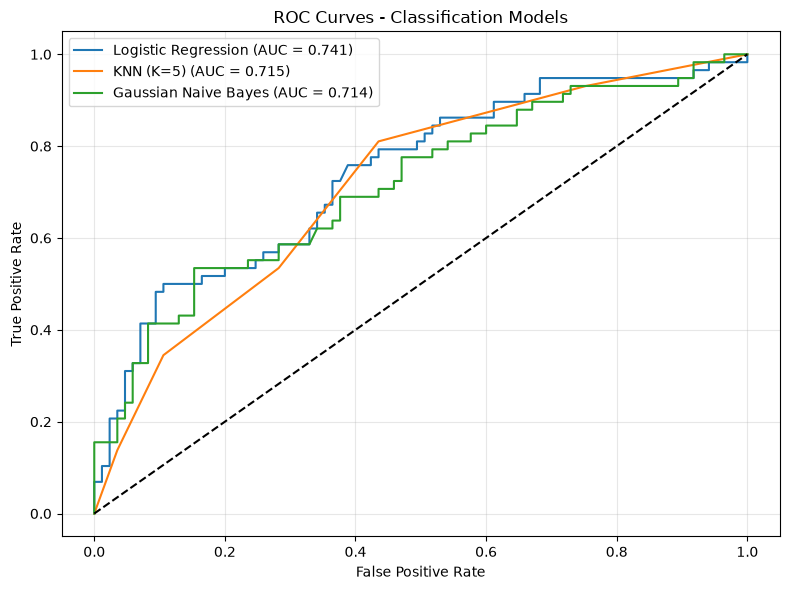

In [8]:
plt.figure(figsize=(8, 6))
for name, prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Classification Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

    K  CV Accuracy   CV F1  CV AUC
0   1       0.6813  0.6189  0.6745
1   3       0.6988  0.6219  0.7196
2   5       0.7058  0.6191  0.7290
3   7       0.7164  0.6152  0.7400
4   9       0.7163  0.6177  0.7514
5  11       0.7058  0.6075  0.7536
6  15       0.7146  0.6127  0.7482


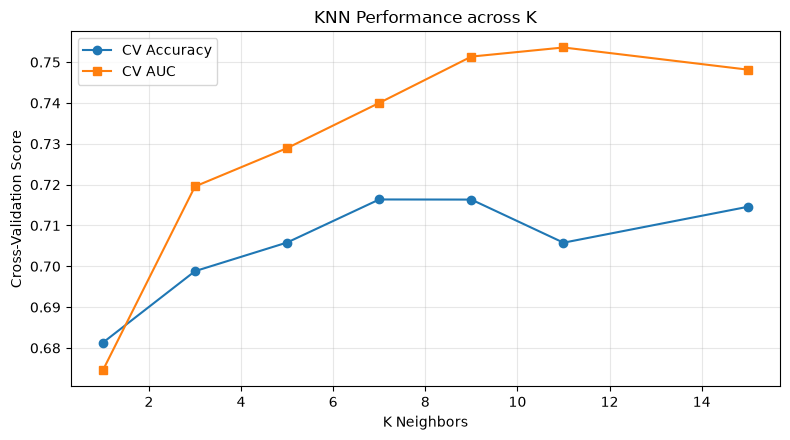

In [9]:
k_rows = []
for k in [1, 3, 5, 7, 9, 11, 15]:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])
    cv = cross_validate(pipe, X_train, y_train, cv=5, scoring=["accuracy", "f1", "roc_auc"])
    k_rows.append({
        "K": k,
        "CV Accuracy": cv["test_accuracy"].mean(),
        "CV F1": cv["test_f1"].mean(),
        "CV AUC": cv["test_roc_auc"].mean()
    })
knn_results = pd.DataFrame(k_rows)
print(knn_results.round(4))

plt.figure(figsize=(8, 4.5))
plt.plot(knn_results["K"], knn_results["CV Accuracy"], marker="o", label="CV Accuracy")
plt.plot(knn_results["K"], knn_results["CV AUC"], marker="s", label="CV AUC")
plt.xlabel("K Neighbors")
plt.ylabel("Cross-Validation Score")
plt.title("KNN Performance across K")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

                      Accuracy  Precision  Recall      F1     AUC
Model                                                            
Logistic Regression     0.7063     0.6905  0.5000  0.5800  0.7406
KNN (K=5)               0.6434     0.5636  0.5345  0.5487  0.7150
Gaussian Naive Bayes    0.6783     0.6579  0.4310  0.5208  0.7144


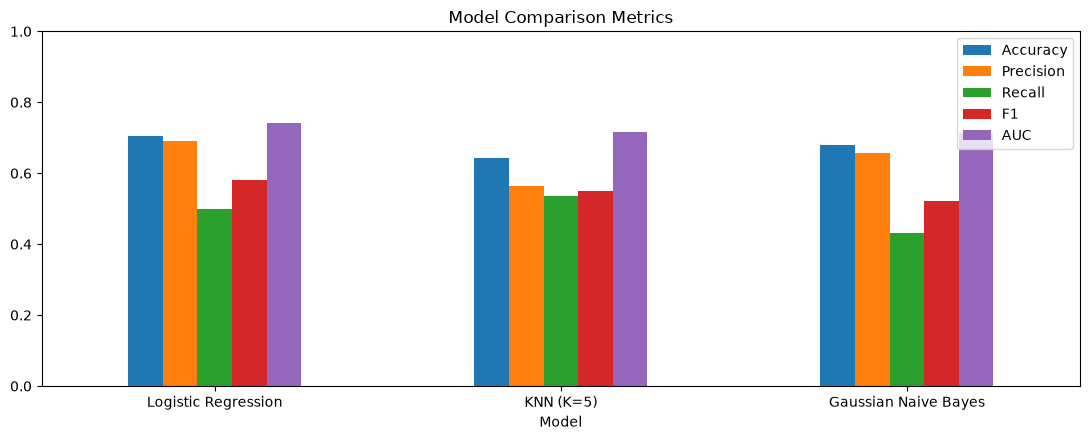

Saved classification results to CSV files.


In [10]:
comparison = pd.DataFrame(results).set_index("Model")
print(comparison.round(4))

comparison.plot(kind="bar", rot=0, figsize=(11, 4.5), ylim=(0, 1))
plt.title("Model Comparison Metrics")
plt.tight_layout()
plt.show()

comparison.to_csv("Experiment_8_Classification_Results.csv")
coef_table.to_csv("Experiment_8_Logistic_Coefficients.csv")
knn_results.to_csv("Experiment_8_KNN_Results.csv", index=False)
print("Saved classification results to CSV files.")